In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/ai4i2020.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (10000, 14)


In [2]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [5]:
df.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

In [7]:
df.isnull().sum()
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
df.iloc[:, -3:].head(10)

,PWF,OSF,RNF
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0
5,0,0,0
6,0,0,0
7,0,0,0
8,0,0,0
9,0,0,0


In [10]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [12]:
# Features we will use for prediction
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target_column = "Machine failure"

X = df[feature_columns]
y = df[target_column]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target:
Machine failure

X shape: (10000, 6)
y shape: (10000,)


In [14]:
print(y.value_counts(normalize=True) * 100)

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [15]:
X.describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


In [16]:
print(X["Type"].value_counts())

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


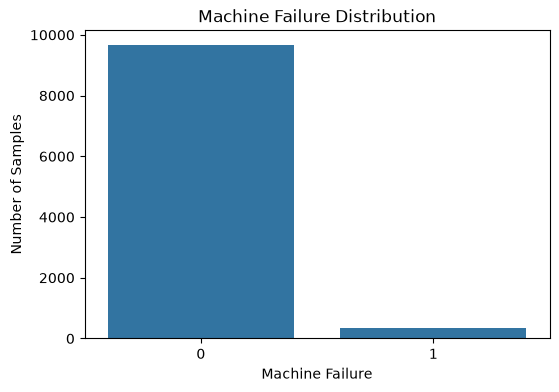

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(x=y)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Samples")

plt.show()

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


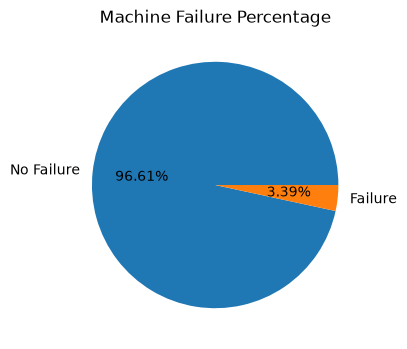

In [19]:
failure_percentage = y.value_counts(normalize=True) * 100

print(failure_percentage)
plt.figure(figsize=(6, 4))

plt.pie(
    failure_percentage,
    labels=["No Failure", "Failure"],
    autopct="%1.2f%%"
)

plt.title("Machine Failure Percentage")

plt.show()

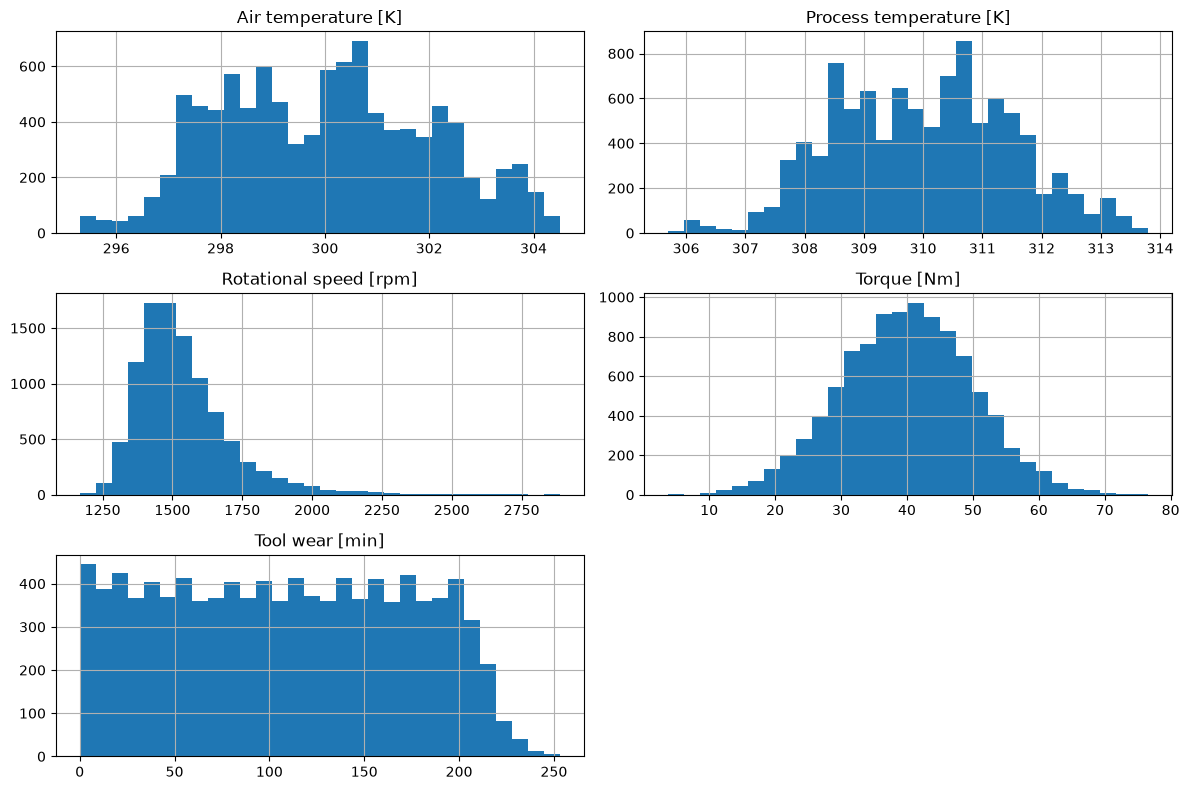

In [20]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numerical_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

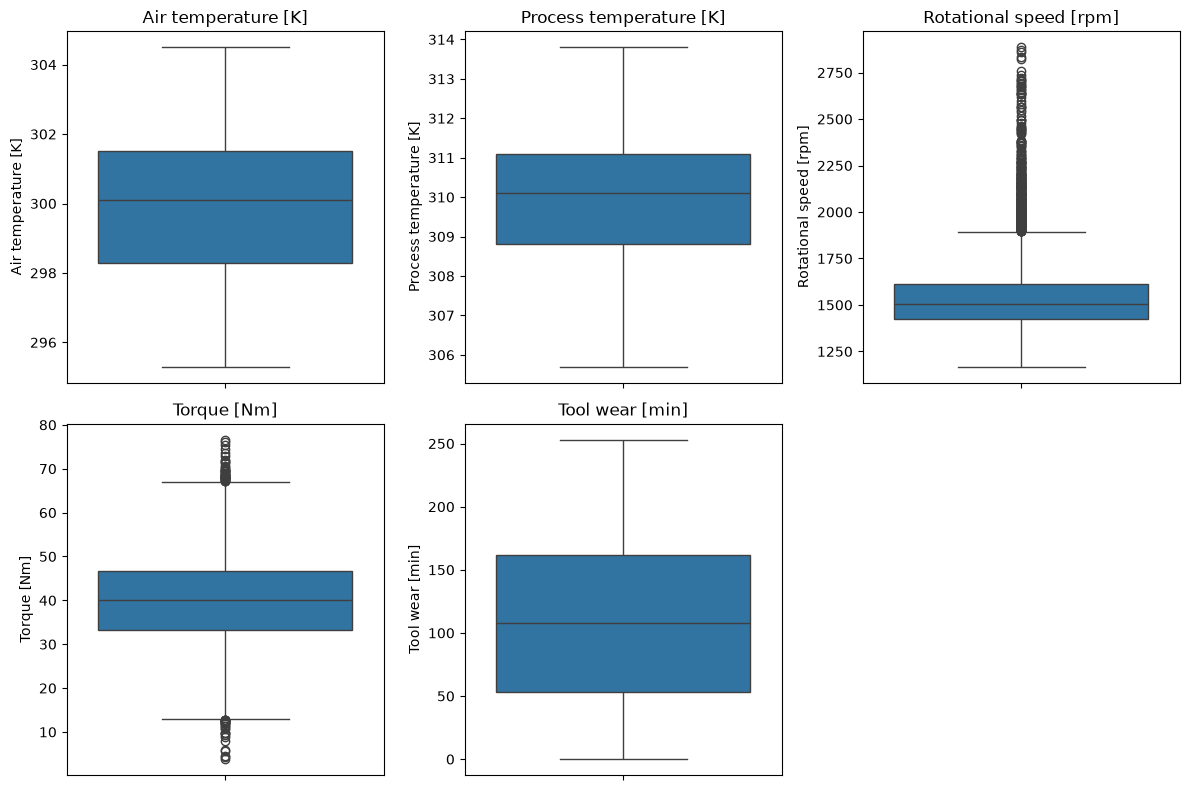

In [21]:
plt.figure(figsize=(12, 8))

for i, feature in enumerate(numerical_features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(y=df[feature])

    plt.title(feature)

plt.tight_layout()
plt.show()

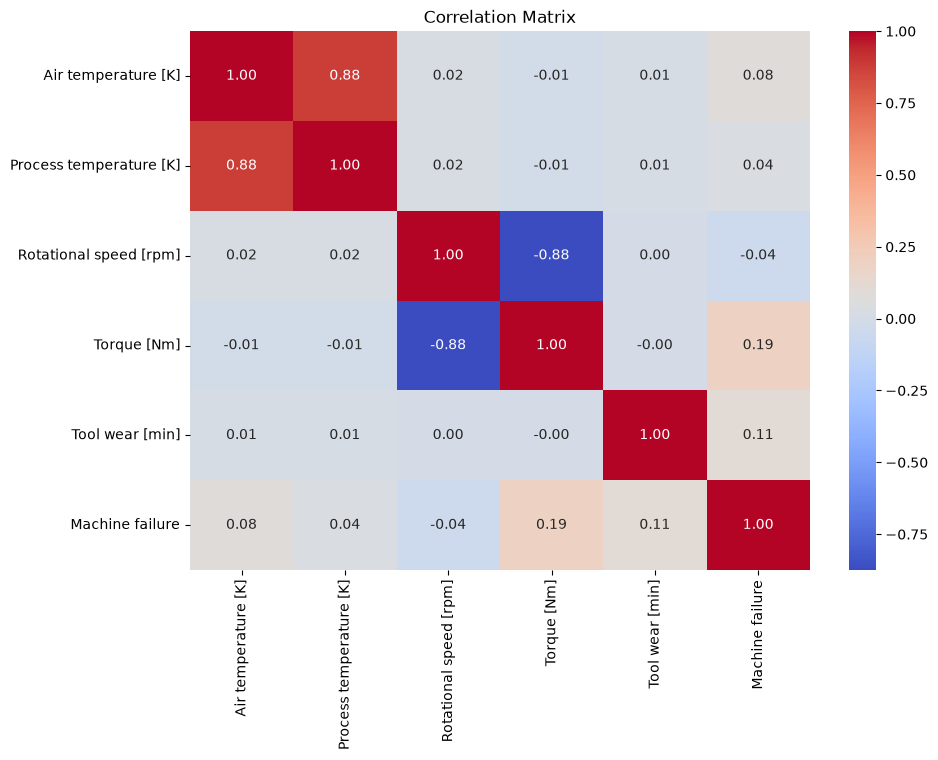

In [22]:
correlation_data = df[numerical_features + ["Machine failure"]]

corr_matrix = correlation_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

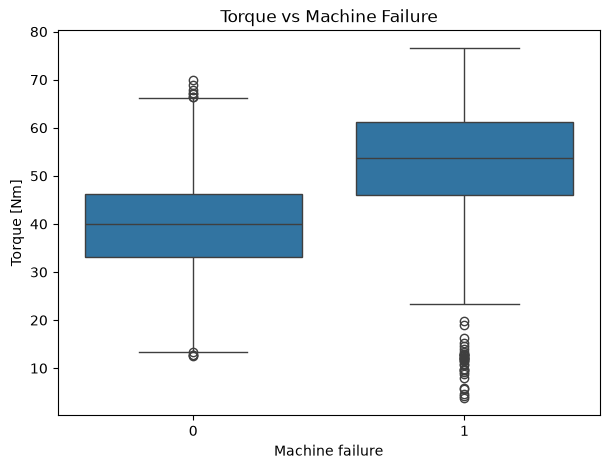

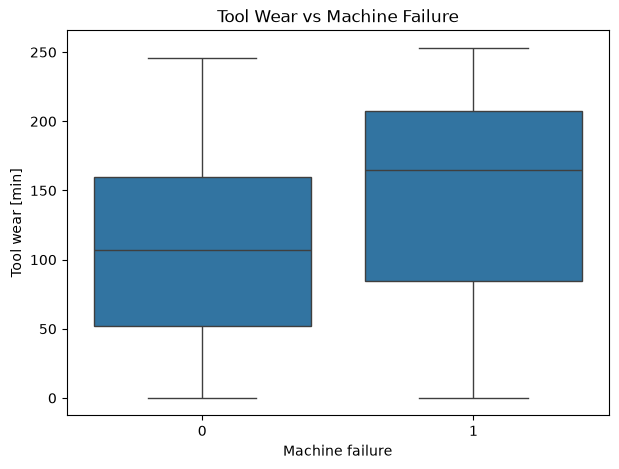

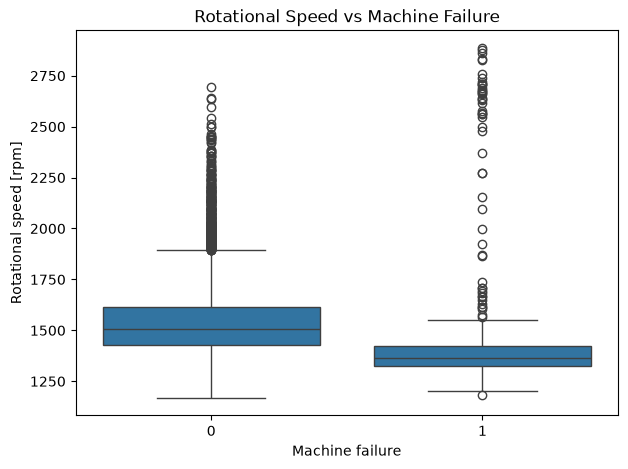

In [26]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Torque [Nm]"
)

plt.title("Torque vs Machine Failure")

plt.show()

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Tool wear [min]"
)

plt.title("Tool Wear vs Machine Failure")

plt.show()

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Rotational speed [rpm]"
)

plt.title("Rotational Speed vs Machine Failure")

plt.show()


Type
H    2.093719
L    3.916667
M    2.769436
Name: Machine failure, dtype: float64


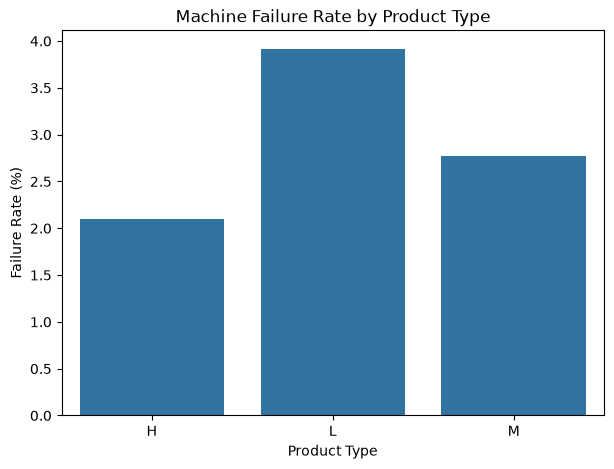

In [27]:
type_failure = df.groupby("Type")["Machine failure"].mean() * 100

print(type_failure)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=type_failure.index,
    y=type_failure.values
)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")

plt.show()

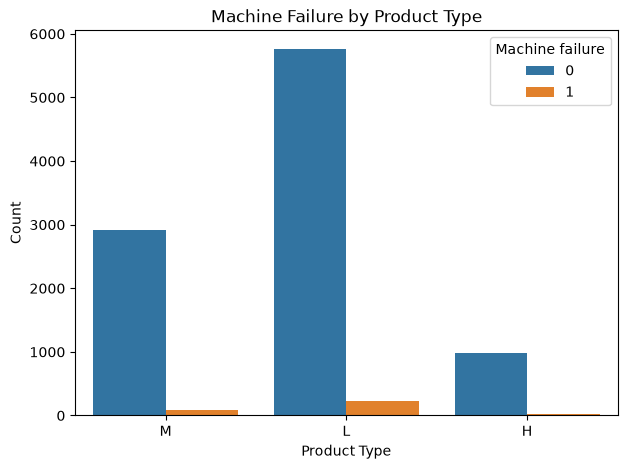

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Type",
    hue="Machine failure"
)

plt.title("Machine Failure by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Count")

plt.show()